# UniAthleteIQ: statistical validation

Notebook 02 reported each result from a single cross-validation run. This notebook asks whether those conclusions **survive proper statistical scrutiny**:

| Question | Method |
|---|---|
| How stable is each score? | 10 repetitions of athlete-grouped 5-fold CV (different fold assignments) |
| How uncertain is it? | 95% CIs from an **athlete-level bootstrap** (whole athletes resampled, because days from one athlete are not independent) |
| Do the ML models beat what coaches already use? | Comparison with untrained baselines: ACWR, the "ACWR > 1.5" rule, 7-day km, perceived exertion |
| Are the differences real? | **Paired** athlete-bootstrap tests, with Holm correction for multiple comparisons |
| Do conclusions depend on arbitrary choices? | Sensitivity to the personal-history window (14/28/56 days) and the football severity cut-off (14/28/56 days) |

All runner experiments use only the 59 **training athletes**. The 15 held-out athletes appear once, in §5.

The model fitting lives in `scripts/run_validation.py` (about 20 minutes, cached), so this notebook only does statistics and plots.

In [1]:
import os
import warnings
warnings.filterwarnings("ignore")

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from uniathleteiq import baselines, paths, plots, stats

plots.apply_style()
pd.set_option("display.precision", 3)
pd.set_option("display.width", 160)
CH = paths.OUTPUT_DIR / "charts" / "v3"
RES = paths.RESULTS_DIR / "validation"
for d in (CH, RES):
    d.mkdir(parents=True, exist_ok=True)

# The cache is produced by scripts/run_validation.py. An alternative cache can be
# pointed to via an environment variable (handy for quick development runs).
cache_path = os.environ.get("VALIDATION_CACHE", paths.OUTPUT_DIR / "cache" / "validation.joblib")
V = joblib.load(cache_path)
R = V["runners"]
y, groups = R["y"], R["groups"]
N_BOOT = 1000
print(f"Seeds: {len(V['seeds'])}   training athletes: {len(np.unique(groups))}   "
      f"athlete-days: {len(y):,}   injuries: {y.sum()}")

Seeds: 10   training athletes: 59   athlete-days: 36,529   injuries: 501


## 1. Every configuration, with uncertainty

- **Split SD**: how much the score moves between the 10 CV repetitions (luck of the fold assignment).
- **95% CI**: athlete-bootstrap interval around the seed-averaged predictions (luck of *which athletes* were recruited). This is the honest error bar.

In [2]:
def summarise(name_cols, oof_by_seed):
    # Average each row's out-of-fold probability over the CV repetitions, then
    # bootstrap athletes around that single, less noisy prediction.
    p_mean = oof_by_seed.mean(axis=0)
    cis = stats.bootstrap_ci(y, p_mean, groups, n_boot=N_BOOT)  # both metrics in one bootstrap
    row = dict(name_cols)
    for metric, ci in cis.items():
        spread = stats.seed_spread(y, oof_by_seed, metric)
        row.update({f"{metric}": ci["estimate"], f"{metric}_lo": ci["ci_low"], f"{metric}_hi": ci["ci_high"],
                    f"{metric}_split_sd": spread["sd"]})
    return row

rows = [summarise({"feature_set": fs, "model": m}, oof) for (fs, m), oof in R["oof"].items()]
rows += [summarise({"feature_set": "baseline (no training)", "model": b}, p[None, :])
         for b, p in R["baselines"].items()]
grid = pd.DataFrame(rows).set_index(["feature_set", "model"])
grid.to_csv(RES / "runners_grid_with_ci.csv")
display(grid[["roc_auc", "roc_auc_lo", "roc_auc_hi", "roc_auc_split_sd", "pr_auc", "pr_auc_lo", "pr_auc_hi"]])

roc_auc  roc_auc_lo  roc_auc_hi  roc_auc_split_sd  pr_auc  pr_auc_lo  pr_auc_hi
feature_set            model                                                                                                        
raw                    Logistic Regression             0.605       0.574       0.638         7.139e-04   0.019      0.015      0.025
                       Random Forest                   0.611       0.574       0.646         4.874e-03   0.019      0.015      0.025
                       XGBoost                         0.617       0.579       0.652         2.578e-03   0.020      0.016      0.028
raw+engineered         Logistic Regression             0.600       0.568       0.634         8.045e-04   0.019      0.015      0.024
                       Random Forest                   0.608       0.567       0.646         1.214e-03   0.019      0.015      0.027
                       XGBoost                         0.616       0.579       0.654         3.000e-03   0.020      0.016      0.027
engineered             Logistic Regression             0.632       0.597       0.668         6.586e-04   0.022      0.017      0.029
                       Random Forest                   0.593       0.558       0.625         1.375e-03   0.019      0.015      0.024
                       XGBoost                         0.613       0.574       0.653         8.368e-04   0.019      0.015      0.025
engineered+personal    Logistic Regression             0.655       0.613       0.696         3.367e-04   0.026      0.018      0.037
                       Random Forest                   0.651       0.611       0.688         2.972e-03   0.023      0.017      0.032
                       XGBoost                         0.661       0.620       0.702         1.673e-03   0.028      0.019      0.040
baseline (no training) ACWR (continuous)               0.543       0.519       0.569         0.000e+00   0.015      0.011      0.019
                       ACWR > 1.5 rule                 0.493       0.477       0.509         0.000e+00   0.014      0.011      0.017
                       7-day km                        0.536       0.502       0.576         0.000e+00   0.014      0.011      0.018
                       Mean perceived exertion (7d)    0.627       0.583       0.672         0.000e+00   0.021      0.015      0.032

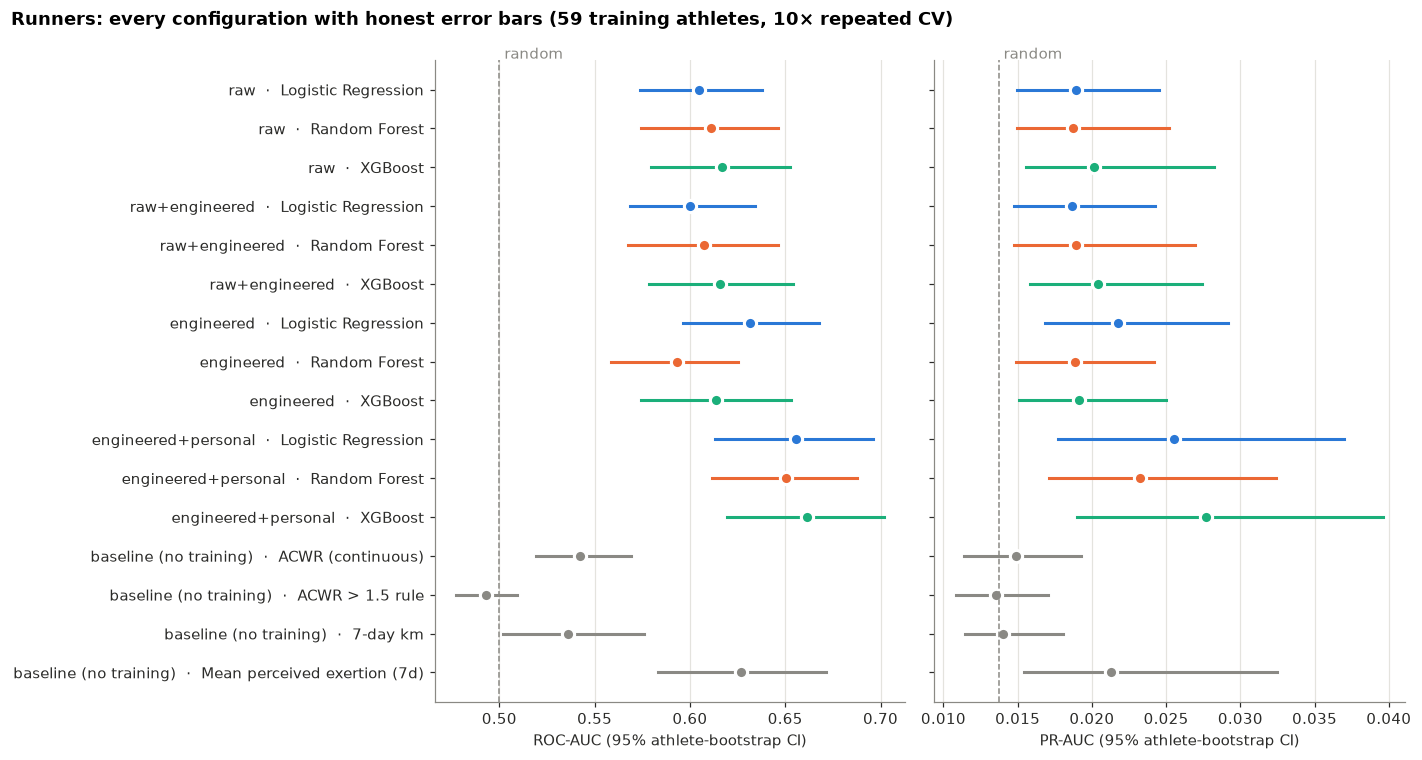

In [3]:
# Forest plot: one row per configuration, point = estimate, bar = 95% athlete-bootstrap CI
fig, axes = plt.subplots(1, 2, figsize=(13, 7), sharey=True)
labels = [f"{fs}  ·  {m}" for fs, m in grid.index]
ypos = np.arange(len(grid))[::-1]
for ax, metric, xlab, ref in [(axes[0], "roc_auc", "ROC-AUC", 0.5),
                              (axes[1], "pr_auc", "PR-AUC", y.mean())]:
    for yy, (idx, r) in zip(ypos, grid.iterrows()):
        color = plots.MUTED if idx[0].startswith("baseline") else plots.color_for(idx[1])
        ax.plot([r[f"{metric}_lo"], r[f"{metric}_hi"]], [yy, yy], color=color, lw=2)
        ax.plot(r[metric], yy, "o", ms=8, color=color, mec="white", mew=2)
    ax.axvline(ref, ls="--", color=plots.MUTED, lw=1)
    ax.text(ref, len(grid) - 0.3, " random", color=plots.MUTED, va="bottom")
    ax.set(xlabel=f"{xlab} (95% athlete-bootstrap CI)")
    ax.grid(axis="y", visible=False)
axes[0].set_yticks(ypos, labels)
fig.suptitle("Runners: every configuration with honest error bars (59 training athletes, 10× repeated CV)",
             x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
fig.savefig(CH / "01_forest_plot.png")
plt.show()

## 2. Which differences are real? (paired tests)

Each comparison scores both configurations on the **same resampled athletes** in every bootstrap round, so differences in athlete difficulty cancel out. p-values are Holm-adjusted within each family of questions.

In [4]:
def p_of(fs, m):
    return R["oof"][(fs, m)].mean(axis=0)

FINAL = ("engineered+personal", "Logistic Regression")
families = {
    "RQ2a: do personal baselines help? (personal vs engineered, same model)": [
        (f"{m}: personal vs engineered", p_of("engineered+personal", m), p_of("engineered", m))
        for m in ["Logistic Regression", "Random Forest", "XGBoost"]],
    "RQ2b: does model choice matter? (on engineered+personal)": [
        ("LR vs RF", p_of(*FINAL), p_of("engineered+personal", "Random Forest")),
        ("LR vs XGBoost", p_of(*FINAL), p_of("engineered+personal", "XGBoost")),
        ("RF vs XGBoost", p_of("engineered+personal", "Random Forest"), p_of("engineered+personal", "XGBoost"))],
    "Does the final model beat untrained baselines?": [
        (f"final LR vs {b}", p_of(*FINAL), p) for b, p in R["baselines"].items()],
}

tests = []
for family, comps in families.items():
    # One paired bootstrap per comparison yields both metrics; Holm is then applied
    # separately per (family, metric) so each family keeps a 5% family-wise error rate.
    paired = {c: stats.paired_bootstrap(y, a, b, groups, n_boot=N_BOOT) for c, a, b in comps}
    for metric in ("roc_auc", "pr_auc"):
        res = [dict(family=family, comparison=c, metric=metric, **paired[c][metric]) for c, _, _ in comps]
        adj = stats.holm_adjust([r["p_value"] for r in res])
        for r, pa in zip(res, adj):
            r["p_holm"] = pa
            r["significant_5pct"] = pa < 0.05
        tests += res
tests = pd.DataFrame(tests)
tests.to_csv(RES / "paired_tests.csv", index=False)
for family, t in tests.groupby("family", sort=False):
    print(family)
    display(t.drop(columns=["family", "n_boot"]).set_index(["comparison", "metric"]))

RQ2a: do personal baselines help? (personal vs engineered, same model)


,,difference,ci_low,ci_high,p_value,p_holm,significant_5pct
comparison,metric,,,,,,
Logistic Regression: personal vs engineered,roc_auc,0.024,3.422e-03,0.047,0.024,0.024,True
Random Forest: personal vs engineered,roc_auc,0.057,3.384e-02,0.080,0.000,0.000,True
XGBoost: personal vs engineered,roc_auc,0.048,3.215e-02,0.064,0.000,0.000,True
Logistic Regression: personal vs engineered,pr_auc,0.004,-7.610e-04,0.012,0.146,0.146,False
Random Forest: personal vs engineered,pr_auc,0.004,7.593e-04,0.010,0.024,0.048,True
XGBoost: personal vs engineered,pr_auc,0.009,2.878e-03,0.016,0.000,0.000,True


RQ2b: does model choice matter? (on engineered+personal)


,,difference,ci_low,ci_high,p_value,p_holm,significant_5pct
comparison,metric,,,,,,
LR vs RF,roc_auc,0.005,-0.017,2.562e-02,0.610,1.000,False
LR vs XGBoost,roc_auc,-0.006,-0.024,1.048e-02,0.500,1.000,False
RF vs XGBoost,roc_auc,-0.011,-0.025,2.980e-03,0.140,0.420,False
LR vs RF,pr_auc,0.002,-0.003,8.038e-03,0.362,0.512,False
LR vs XGBoost,pr_auc,-0.002,-0.007,1.368e-03,0.256,0.512,False
RF vs XGBoost,pr_auc,-0.004,-0.010,3.298e-05,0.052,0.156,False


Does the final model beat untrained baselines?


,,difference,ci_low,ci_high,p_value,p_holm,significant_5pct
comparison,metric,,,,,,
final LR vs ACWR (continuous),roc_auc,0.113,6.534e-02,0.155,0.000,0.000,True
final LR vs ACWR > 1.5 rule,roc_auc,0.162,1.147e-01,0.212,0.000,0.000,True
final LR vs 7-day km,roc_auc,0.120,6.734e-02,0.167,0.000,0.000,True
final LR vs Mean perceived exertion (7d),roc_auc,0.029,-4.087e-03,0.061,0.076,0.076,False
final LR vs ACWR (continuous),pr_auc,0.011,4.278e-03,0.021,0.000,0.000,True
final LR vs ACWR > 1.5 rule,pr_auc,0.012,6.031e-03,0.022,0.000,0.000,True
final LR vs 7-day km,pr_auc,0.012,4.820e-03,0.021,0.000,0.000,True
final LR vs Mean perceived exertion (7d),pr_auc,0.004,-8.294e-04,0.010,0.104,0.104,False


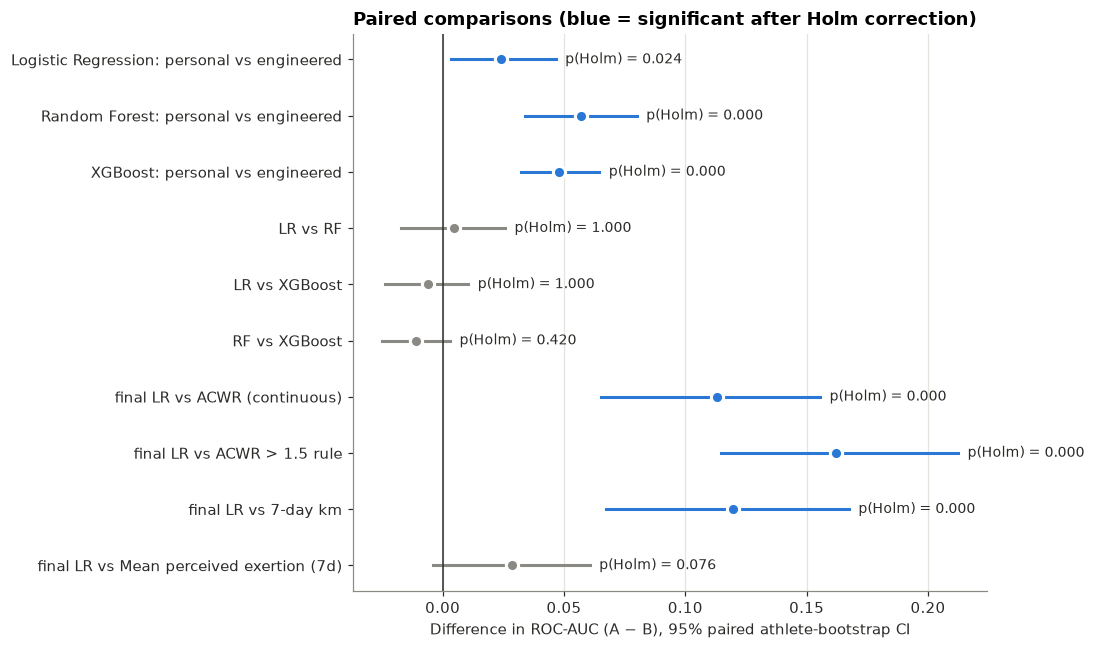

In [5]:
# Visual summary of the ROC-AUC differences with their CIs
t = tests[tests.metric == "roc_auc"].reset_index(drop=True)
fig, ax = plt.subplots(figsize=(10, 0.45 * len(t) + 1.5))
ypos = np.arange(len(t))[::-1]
for yy, (_, r) in zip(ypos, t.iterrows()):
    color = plots.SERIES[0] if r.significant_5pct else plots.MUTED
    ax.plot([r.ci_low, r.ci_high], [yy, yy], color=color, lw=2)
    ax.plot(r.difference, yy, "o", ms=8, color=color, mec="white", mew=2)
    ax.text(max(r.ci_high, 0) + 0.004, yy, f"p(Holm) = {r.p_holm:.3f}", va="center", color=plots.TEXT, fontsize=9)
ax.axvline(0, color=plots.TEXT, lw=1)
ax.set_yticks(ypos, t.comparison)
ax.set(xlabel="Difference in ROC-AUC (A − B), 95% paired athlete-bootstrap CI")
ax.grid(axis="y", visible=False)
ax.set_title("Paired comparisons (blue = significant after Holm correction)")
fig.tight_layout()
fig.savefig(CH / "02_paired_differences.png")
plt.show()

## 3. Sensitivity analyses

**Personal-history window.** Personal z-scores need some history first. Does the 28-day choice matter?

In [6]:
sens = pd.DataFrame([summarise({"min_history_days": k}, oof) for k, oof in R["sensitivity_min_history"].items()])
sens = sens.set_index("min_history_days")
sens.to_csv(RES / "sensitivity_min_history.csv")
display(sens[["roc_auc", "roc_auc_lo", "roc_auc_hi", "pr_auc", "pr_auc_lo", "pr_auc_hi"]])

,roc_auc,roc_auc_lo,roc_auc_hi,pr_auc,pr_auc_lo,pr_auc_hi
min_history_days,,,,,,
14,0.656,0.615,0.696,0.025,0.018,0.037
28,0.655,0.613,0.696,0.026,0.018,0.037
56,0.657,0.615,0.700,0.026,0.018,0.038


**Football severity cut-off.** "Severe" is defined as more than 28 days out (Fuller et al., 2006). Do the conclusions change at 14 or 56 days?

In [7]:
fb_rows = []
for days, F in V["football"].items():
    for name, oof in F["oof"].items():
        ci = stats.bootstrap_ci(F["y"], oof.mean(axis=0), F["groups"], n_boot=N_BOOT)["roc_auc"]
        fb_rows.append({"severe_if_more_than_days": days, "model": name, "positive_rate": F["y"].mean(), **ci})
    ci = stats.bootstrap_ci(F["y"], F["baseline_prev_season_days"], F["groups"], n_boot=N_BOOT)["roc_auc"]
    fb_rows.append({"severe_if_more_than_days": days, "model": "Baseline: days injured last season",
                    "positive_rate": F["y"].mean(), **ci})
fb = pd.DataFrame(fb_rows).set_index(["severe_if_more_than_days", "model"]).drop(columns="n_boot")
fb.to_csv(RES / "sensitivity_football_threshold.csv")
display(fb)

positive_rate  estimate  ci_low  ci_high
severe_if_more_than_days model                                                                       
14                       Logistic Regression                         0.840     0.581   0.530    0.628
                         Random Forest                               0.840     0.592   0.544    0.638
                         XGBoost                                     0.840     0.591   0.539    0.642
                         Baseline: days injured last season          0.840     0.558   0.511    0.603
28                       Logistic Regression                         0.681     0.605   0.559    0.646
                         Random Forest                               0.681     0.601   0.560    0.640
                         XGBoost                                     0.681     0.611   0.566    0.649
                         Baseline: days injured last season          0.681     0.543   0.500    0.582
56                       Logistic Regression                         0.438     0.575   0.536    0.613
                         Random Forest                               0.438     0.586   0.546    0.621
                         XGBoost                                     0.438     0.617   0.582    0.650
                         Baseline: days injured last season          0.438     0.526   0.487    0.560

## 4. Final check on the 15 held-out athletes

This is the confirmatory test. Only 15 athletes means wide intervals, which is exactly why the CIs are shown.

In [8]:
H = R["holdout"]

def flat_ci(p):
    # {"roc_auc": {...}, "pr_auc": {...}} -> one flat row: roc_auc_estimate, roc_auc_ci_low, ...
    return {f"{m}_{k}": v for m, d in stats.bootstrap_ci(H["y"], p, H["groups"], n_boot=N_BOOT).items()
            for k, v in d.items() if k != "n_boot"}

hold = [{"score": "Final model (LR, engineered+personal)", **flat_ci(H["model"])}]
hold += [{"score": f"Baseline: {b}", **flat_ci(p)} for b, p in H["baselines"].items()]
hold = pd.DataFrame(hold).set_index("score")
hold.to_csv(RES / "holdout_with_ci.csv")
display(hold)

rule = baselines.rule_metrics(H["y"], H["baselines"][f"ACWR > {baselines.ACWR_DANGER} rule"])
print(f"ACWR > {baselines.ACWR_DANGER} rule on held-out athletes: flags {rule['flagged_rate']:.1%} of days, "
      f"catches {rule['recall']:.1%} of injuries, precision {rule['precision']:.2%}")
pair = stats.paired_bootstrap(H["y"], H["model"], H["baselines"]["ACWR (continuous)"], H["groups"],
                              n_boot=N_BOOT)["roc_auc"]
print(f"Final model minus ACWR (ROC-AUC) on held-out athletes: {pair['difference']:+.3f} "
      f"[{pair['ci_low']:+.3f}, {pair['ci_high']:+.3f}], p = {pair['p_value']:.3f}")

,roc_auc_estimate,roc_auc_ci_low,roc_auc_ci_high,pr_auc_estimate,pr_auc_ci_low,pr_auc_ci_high
score,,,,,,
"Final model (LR, engineered+personal)",0.620,0.522,0.698,0.020,0.010,0.027
Baseline: ACWR (continuous),0.554,0.506,0.616,0.014,0.009,0.022
Baseline: ACWR > 1.5 rule,0.527,0.471,0.595,0.013,0.008,0.019
Baseline: 7-day km,0.547,0.483,0.627,0.012,0.008,0.019
Baseline: Mean perceived exertion (7d),0.575,0.464,0.678,0.015,0.008,0.031


ACWR > 1.5 rule on held-out athletes: flags 9.5% of days, catches 14.9% of injuries, precision 1.88%


Final model minus ACWR (ROC-AUC) on held-out athletes: +0.066 [-0.069, +0.161], p = 0.342


## 5. Findings

All numbers are from 59 training athletes, 10× repeated athlete-grouped CV, with 95% athlete-bootstrap CIs. The held-out test uses 15 further athletes.

1. **Split luck is negligible; athlete luck is not.** Re-shuffling CV folds moves ROC-AUC by an SD of ≤ 0.005, but the athlete-bootstrap CIs are about ±0.04. Uncertainty comes from *which athletes* were recruited, so more athletes, not more tuning, is what would sharpen the estimates.
2. **RQ2a: personal baselines help significantly.** Adding deviation-from-own-normal features raises ROC-AUC for every model: LR +0.024 (95% CI 0.003–0.047), RF +0.057, XGBoost +0.048, all significant after Holm correction. The PR-AUC gain is significant for RF and XGBoost, but not for LR.
3. **RQ2b: model choice does not matter.** On the final feature set, no pair of models differs significantly (all Holm-adjusted p ≥ 0.15). The simplest, fully explainable model (logistic regression) is therefore justified.
4. **The model clearly beats common workload rules.** It improves ROC-AUC over continuous ACWR by +0.11, over 7-day km by +0.12, and over the popular **"ACWR > 1.5" rule by +0.16**. That rule alone performs at chance in this data (ROC-AUC 0.49).
5. **Subjective effort carries most of the signal.** A single number, the athlete's mean *perceived exertion* over 7 days, reaches ROC-AUC 0.63. The full model's advantage over it (+0.03) is **not significant** (p = 0.08). The practical lesson: asking athletes how hard training felt is the most valuable thing a monitoring system can collect.
6. **Conclusions are robust to arbitrary choices.** The personal-history window (14, 28 or 56 days) changes ROC-AUC by < 0.003. In football, all models beat the "days injured last season" baseline at every severity cut-off (14, 28 and 56 days).
7. **Held-out athletes:** ROC-AUC 0.62 (95% CI 0.52–0.70). With only 15 athletes the CI is wide, and the advantage over ACWR (+0.07) is not significant on this small set. That is exactly why the repeated-CV comparisons above carry the main evidence.

**For a paper:** findings 2–5 answer RQ2 and add a practically important negative result about the ACWR rule. The honest headline is *"modest but real signal, driven by personal baselines and perceived effort, not by model complexity."*